In [1]:

import numpy as np # linear algebra
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
import kagglehub

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
train = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")
test = pd.read_csv("/kaggle/input/competitions/titanic/test.csv")
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

# Data overview

* AGE missed data units - 177
* Cabin - 687
* Embarked - 2

**In general, missed data is spread across Age and Cabin number. There are two missed Embarked values, but I will find them via most popular harbor. There are no more missing data**

In [3]:
train["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

**Division by gender(float)**

* male 0.647587
* female    0.352413

**Division by gender(int)**

* male      577
* female    314

In [4]:
train.describe(include="object")

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


In [5]:
train.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [6]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
train.groupby("Pclass")["Survived"].count()

Pclass
1    216
2    184
3    491
Name: Survived, dtype: int64

In [8]:
train.groupby("Pclass")["Cabin"].count()

Pclass
1    176
2     16
3     12
Name: Cabin, dtype: int64

In [9]:
train.groupby("Survived").count()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Survived,,,,,,,,,,,
0,549,549,549,549,424,549,549,549,549,68,549
1,342,342,342,342,290,342,342,342,342,136,340


# EDA Visual


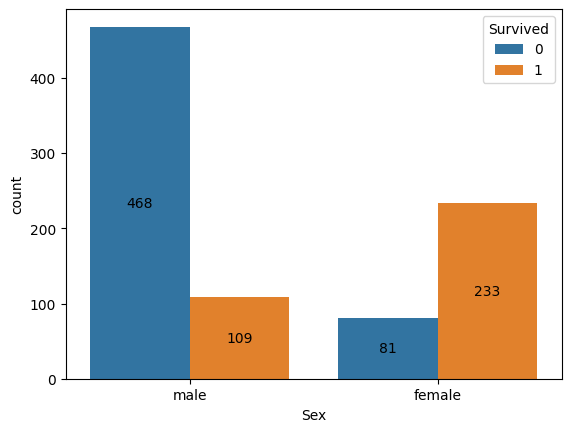

In [10]:
ax0 = sns.countplot(data=train, x="Sex", hue="Survived")
for ax in ax0.containers:
    ax0.bar_label(ax, fmt="%.0f", label_type="center")
plt.show()

**468 of 549 perished were men**


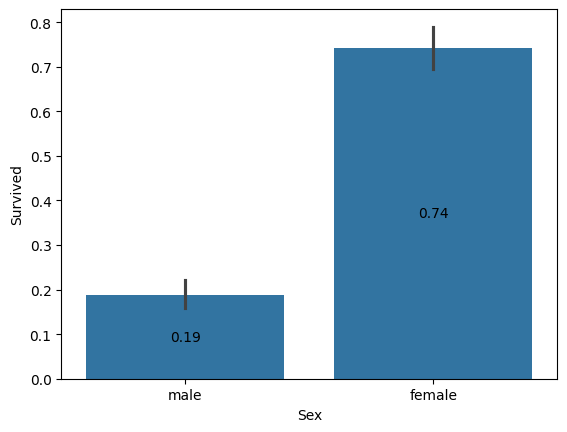

In [11]:
ax1 = sns.barplot(data=train, x="Sex",y="Survived")
ax1.bar_label(ax1.containers[0], fmt="%.2f",label_type="center")
plt.show()

**Specifically here, it shows that survival rate of men = 0,19, while women = 0.74**

**Almost 4 times difference**

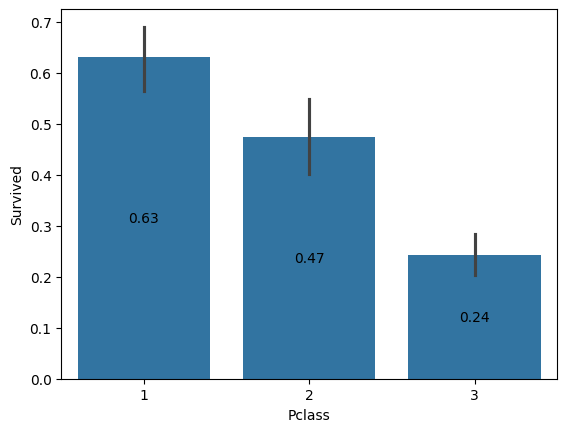

In [12]:
ax2 = sns.barplot(data=train, x="Pclass",y="Survived")
ax2.bar_label(ax2.containers[0], fmt="%.2f",label_type="center")
plt.show()

**Survival rates by ticket class are shown here**

**difference between 1st and 3rd class is almost 3 times**

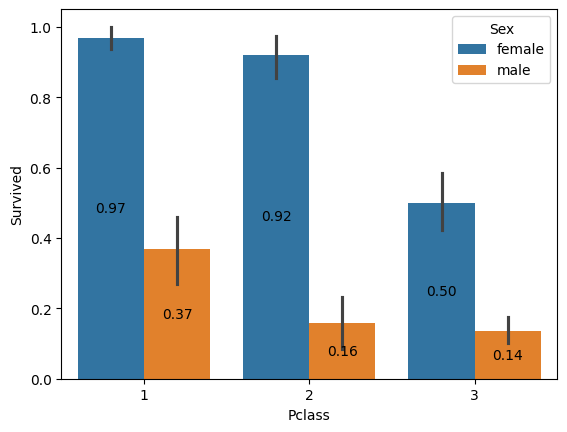

In [13]:
ax2 = sns.barplot(data=train, x="Pclass", hue="Sex", y="Survived")
for bars in ax2.containers:
    ax2.bar_label(bars, fmt="%.2f",label_type="center")
plt.show()

**Survival rates of gender and ticket class combined**

**Group most likely to survive - 1st class females** **difference beetween 2nd and 3rd ticket class among women is 92%->50%**

**Group least likely to survive - 3rd class males** **difference beetween 1st and 2nd ticket class among men is 37%->16%**

**(~7 times difference)**

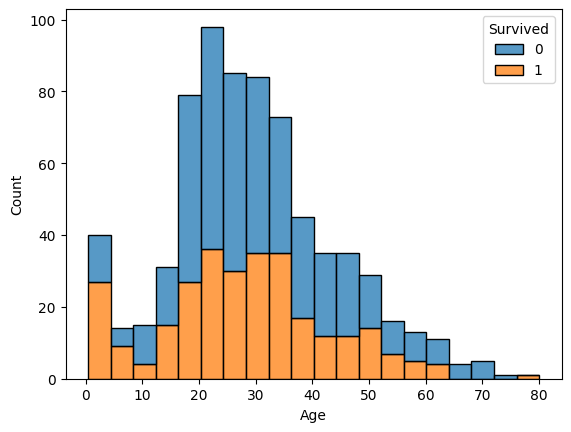

In [14]:
sns.histplot(data=train, x="Age", hue="Survived", multiple="stack")
plt.show()

In [15]:
train["AgeGroup"] = pd.cut(train["Age"], bins=[0,12,18,60,80], labels=["kids", "teenagers", "adults", "elderly"])
train["AgeGroup"].value_counts()

AgeGroup
adults       553
teenagers     70
kids          69
elderly       22
Name: count, dtype: int64

**Survival rates by age distribution**

**For kids it is most likely to survive, for elderly about 23%(not linear! not enough data) with about 58 and 23 per cent, respectively** 

**Adults have about 39% chance of survival**

In [ ]:
ax3 = sns.barplot(data=train, x="AgeGroup", y="Survived")
for bars in ax3.containers:
    ax3.bar_label(bars, fmt="%.2f", label_type="center")

## Missing data ##
- **177(20%) of age column is missing**
- **77% of cabin column is missing.especially among 3rd ticket class (only 12 out of 491 3rd class passengers have a cabin recorded)**

In [ ]:
train[train["Name"].str.contains("Master")].count()

In [ ]:
train[train["Name"].str.contains("Master")]["Age"].describe()

In [ ]:
train["Age"].median()

In [ ]:
train[train["Name"].str.contains("Miss")].count()

Miss 188 median 21 years

Mrs 129 median 35 years

In [ ]:
train.groupby(["AgeGroup", "Sex"], observed=True)["Survived"].agg(["mean", "count"]).unstack()

In [ ]:
train[train["Name"].str.contains("Master")]["Pclass"].value_counts()

In [ ]:
train[train["Embarked"].isnull()]

In [ ]:
train['Embarked'] = train["Embarked"].fillna('S')
train['Embarked'].isnull().sum()

In [ ]:
rare_titles = ["Dr", "Rev", "Major", "Col", "Countess", "Capt", "Sir",
               "Lady", "Don", "Jonkheer", "Dona"]
train["Title"] = train["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
train["Title"] = train["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
test["Title"] = test["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
test["Title"] = test["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})

In [ ]:
train["Title"] = train["Title"].replace(rare_titles, "Rare")
test["Title"] = test["Title"].replace(rare_titles, "Rare")

In [ ]:
train["Age"] = train["Age"].fillna(train.groupby("Title")["Age"].transform("median"))

In [ ]:
train['HasCabin'] = train['Cabin'].notnull().astype(int)
train[['Cabin', 'HasCabin']].head(10)

In [ ]:
train.groupby('HasCabin')['Survived'].mean()

In [ ]:
ax = sns.barplot(data=train, x='HasCabin', y='Survived')


In [ ]:
train.groupby('Pclass')['HasCabin'].mean()

In [ ]:
train.groupby(['Pclass', 'HasCabin'])['Survived'].agg(['mean', 'count'])


**Judging by the HasCabin attribute, survival rates rise significantly, especially among 2nd and 3rd Pclass. But 2nd and 3rd Pclass have only a few people with HasCabin attribute. i.e. We cannot rely on this data. However 1st Pclass has a lot of people with HasCabin attribute and enough people with no cabin. In conclusion, the future model will include HasCabin attribute in its calculations, but only for 1st Pclass**


In [ ]:
train["Sex"] = train["Sex"].map({'male': 1, 'female': 0})
test["Sex"] = test["Sex"].map({'male': 1, 'female': 0})

In [ ]:
train["Sex"].value_counts()

In [ ]:
# Семья (train)
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1
train["IsAlone"] = (train["FamilySize"] == 1).astype(int)

# test.csv

In [ ]:
test["HasCabin"] = test["Cabin"].notnull().astype(int)

In [ ]:
age_medians = train.groupby("Title")["Age"].median()
test["Age"] = test["Age"].fillna(test["Title"].map(age_medians))

In [ ]:
test["Fare"] = test["Fare"].fillna(train["Fare"].median())

In [ ]:
test["FamilySize"] = test["SibSp"] + test["Parch"] + 1
test["IsAlone"] = (test["FamilySize"] == 1).astype(int)

In [ ]:
test_ids = test["PassengerId"]

In [ ]:
drop_cols = ["PassengerId", "Name", "Ticket", "Cabin", "SibSp", "Parch"]
train = train.drop(columns=drop_cols)
test = test.drop(columns=drop_cols)
train = train.drop(columns=["AgeGroup"])

In [ ]:
train = pd.get_dummies(train, columns=['Embarked', 'Title'], dtype=int)
test = pd.get_dummies(test, columns=['Embarked', 'Title'], dtype=int)

# Logistic Regression

In [ ]:
X = train.drop(columns=['Survived'])
y = train['Survived']
test = test[X.columns]
print(X.shape, y.shape, test.shape)
print(list(X.columns) == list(test.columns))
X_test = test

In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
model.fit(X_train, y_train)

In [ ]:
from sklearn.metrics import accuracy_score

val_pred = model.predict(X_val)
accuracy_score(y_val, val_pred)

In [ ]:
accuracy_score(y_val, 1 - X_val["Sex"])

In [ ]:
pd.Series(model.coef_[0], index=X.columns).sort_values()

In [ ]:
final_model = LogisticRegression(max_iter=1000)
final_model.fit(X, y)

In [ ]:
LR_test = final_model.predict(X_test)

In [ ]:
submission = pd.DataFrame({'PassengerId': test_ids, 'Survived': LR_test})

In [ ]:
submission.to_csv('submission.csv', index=False)

In [ ]:
train.groupby("Sex")['Survived']

# DecisionTree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

In [ ]:
print('Learning:', accuracy_score(y_train, tree.predict(X_train)))
print('Checking:', accuracy_score(y_val, tree.predict(X_val)))

**Visual representation**

In [ ]:
from sklearn.tree import plot_tree
plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=X.columns, class_names=['died', 'survived'],
         filled=True, max_depth=2,fontsize=10)
plt.show()

# RandomForest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)
rf.fit(X_train, y_train)

In [ ]:
print('Learning:', accuracy_score(y_train, rf.predict(X_train)))
print('Checking:', accuracy_score(y_val, rf.predict(X_val)))

In [ ]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importances

**experiment with passenger_id**

In [ ]:
raw_train = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")

X_id = X.copy()
X_id["PassengerId"] = raw_train["PassengerId"]

Xi_train, Xi_val, yi_train, yi_val = train_test_split(X_id, y, test_size=0.2, random_state=42)

rf_id = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)
rf_id.fit(Xi_train, yi_train)

print("Проверка с PassengerId:", accuracy_score(yi_val, rf_id.predict(Xi_val)))
print(pd.Series(rf_id.feature_importances_, index=X_id.columns).sort_values(ascending=False))

In [ ]:
rfF = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)
rfF.fit(X, y)

In [ ]:
treeF = DecisionTreeClassifier(max_depth=4, random_state=42)
treeF.fit(X, y)

In [ ]:
RF_test = rfF.predict(X_test)

In [ ]:
TE_test = treeF.predict(X_test)

In [ ]:
submissionTE = pd.DataFrame({'PassengerId': test_ids, 'Survived': TE_test})

In [ ]:
submissionRF = pd.DataFrame({'PassengerId': test_ids, 'Survived': RF_test})

In [ ]:
submissionTE.to_csv('submissionTE.csv', index=False)

In [ ]:
submissionRF.to_csv('submissionRF.csv', index=False)

# Errors analysis

In [ ]:
val_pred_rf = rf.predict(X_val)
mask = val_pred_rf != y_val.values
print("Errors:", mask.sum())

In [ ]:
errors = raw_train.loc[X_val.index[mask],
                       ["Name", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin", "Survived"]].copy()
errors["Predicted"] = val_pred_rf[mask]
errors["Prob_survive"] = rf.predict_proba(X_val)[:, 1][mask].round(2)
errors.head(10)

# Test hypothesis

In [ ]:
def val_acc(cols):
    m = LogisticRegression(max_iter=1000)
    m.fit(X_train[cols], y_train)
    return accuracy_score(y_val, m.predict(X_val[cols]))

In [ ]:
val_acc(['Sex', 'Pclass'])


In [ ]:
all_cols = list(X.columns)

In [ ]:
no_title = [c for c in all_cols if not c.startswith('Title_')]
no_alone = [c for c in all_cols if c != 'IsAlone']
print('All:', val_acc(all_cols))
print('No Title:', val_acc(no_title))
print('No IsAlone:', val_acc(no_alone))